## Setup — Cell 1: Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from google.colab import files
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")

Libraries imported successfully.


## Setup — Cell 2: Upload the CSV

In [ ]:
df_raw = pd.read_csv('/content/retail_stock_insight_synthetic_10000x20.csv')
print("Dataset loaded successfully!")
print("Shape:", df_raw.shape)
display(df_raw.head())

Dataset loaded successfully!
Shape: (10000, 20)


,transaction_id,date,store_id,city,store_type,region,product_id,product_name,category,brand,unit_price,quantity_sold,discount_pct,promotion,customer_count,weather,holiday,weekend,opening_stock,closing_stock
0,T00001,2025-02-02,S002,Bengaluru,Supermarket,South,P002,Wheat Flour 2kg,Grocery,GrainHouse,106.84,10,0,No,803,Hot,No,1,52,62
1,T00002,2025-10-10,S022,Coimbatore,Supermarket,South,P020,Paper Towels,Household,CleanPlus,76.24,10,0,No,859,Hot,No,0,114,104
2,T00003,2025-08-27,S007,Kochi,Supermarket,South,P011,Shampoo 180ml,Personal Care,GlowCare,116.83,9,0,No,1035,Cloudy,No,0,132,123
3,T00004,2025-06-10,S022,Madurai,Hypermarket,South,P020,Paper Towels,Household,CleanPlus,72.50,14,8,Yes,1069,Windy,No,0,143,149
4,T00005,2025-06-08,S017,Bengaluru,Supermarket,South,P009,Laundry Detergent,Household,CleanPlus,193.00,7,9,Yes,463,NaN,No,1,74,107


## Round 1 — Cell 3: Understand the dataset

In [ ]:
print("Rows and columns:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())
print("\nData types and non-null counts:")
df_raw.info()
print("\nMissing values by column:")
display(df_raw.isna().sum().to_frame("missing_values"))
print("\nExact duplicate rows:", df_raw.duplicated().sum())
print("\nNumeric summary:")
display(df_raw.describe().T)

Rows and columns: (10000, 20)

Column names:
['transaction_id', 'date', 'store_id', 'city', 'store_type', 'region', 'product_id', 'product_name', 'category', 'brand', 'unit_price', 'quantity_sold', 'discount_pct', 'promotion', 'customer_count', 'weather', 'holiday', 'weekend', 'opening_stock', 'closing_stock']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  10000 non-null  object 
 1   date            10000 non-null  object 
 2   store_id        10000 non-null  object 
 3   city            10000 non-null  object 
 4   store_type      10000 non-null  object 
 5   region          10000 non-null  object 
 6   product_id      10000 non-null  object 
 7   product_name    9950 non-null   object 
 8   category        10000 non-null  object 
 9   brand           10000 non-null  object 
 10  un

,missing_values
transaction_id,0
date,0
store_id,0
city,0
store_type,0
region,0
product_id,0
product_name,50
category,0
brand,0



Exact duplicate rows: 20

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
unit_price,10000.0,112.130569,87.952441,-10.0,42.79,93.295,148.3625,453.59
quantity_sold,10000.0,8.962200,3.484334,-3.0,6.00,9.000,11.0000,29.00
discount_pct,10000.0,5.864800,8.589814,0.0,0.00,0.000,8.0000,30.00
customer_count,10000.0,638.628000,322.993852,80.0,359.00,637.000,919.0000,1200.00
weekend,10000.0,0.281400,0.449705,0.0,0.00,0.000,1.0000,1.00
opening_stock,10000.0,81.994800,39.555291,15.0,47.00,82.000,117.0000,150.00
closing_stock,10000.0,92.937900,45.961746,0.0,57.00,92.000,127.0000,206.00


## Round 1 — Cell 4: Clean and prepare data

In [ ]:
df = df_raw.copy()
initial_rows = len(df)

# Remove exact duplicate rows
duplicates_removed = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

# Standardize inconsistent category labels
category_map = {
    "grocery": "Grocery", "GROCERY": "Grocery",
    "dairy": "Dairy", "DAIRY": "Dairy",
    "snack": "Snacks", "SNACKS": "Snacks",
    "beverages": "Beverages", "BEVERAGE": "Beverages",
    "house hold": "Household", "HOUSEHOLD": "Household",
    "personal care": "Personal Care", "Personal care": "Personal Care",
    "fresh produce": "Fresh Produce", "Fresh produce": "Fresh Produce"
}
df["category"] = df["category"].replace(category_map)

# Fill missing weather with its mode
weather_missing_before = int(df["weather"].isna().sum())
if df["weather"].notna().any():
    df["weather"] = df["weather"].fillna(df["weather"].mode().iloc[0])

# Fill missing product names using the most common product name for each product_id
product_name_map = (
    df.dropna(subset=["product_name"])
      .groupby("product_id")["product_name"]
      .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else s.iloc[0])
      .to_dict()
)
product_missing_before = int(df["product_name"].isna().sum())
df["product_name"] = df["product_name"].fillna(df["product_id"].map(product_name_map))
df["product_name"] = df["product_name"].fillna("Unknown Product")

# Convert key numeric fields; invalid or non-positive prices/quantities are removed
for col in ["unit_price", "quantity_sold", "discount_pct", "customer_count",
            "opening_stock", "closing_stock"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

invalid_mask = (
    df["unit_price"].isna() | (df["unit_price"] <= 0) |
    df["quantity_sold"].isna() | (df["quantity_sold"] <= 0)
)
invalid_rows_removed = int(invalid_mask.sum())
df = df.loc[~invalid_mask].copy()

# Parse dates and derive useful features
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.dropna(subset=["date"]).copy()
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.dayofweek
df["revenue"] = df["unit_price"] * df["quantity_sold"] * (1 - df["discount_pct"] / 100)
df["stock_status"] = np.where(df["closing_stock"] <= 20, "Low Stock", "Stock Available")

print(f"Rows before cleaning: {initial_rows:,}")
print(f"Exact duplicates removed: {duplicates_removed:,}")
print(f"Rows with invalid price/quantity removed: {invalid_rows_removed:,}")
print(f"Missing weather values found: {weather_missing_before:,}")
print(f"Missing product names found: {product_missing_before:,}")
print(f"Rows after cleaning: {len(df):,}")
print("Remaining missing values:", int(df.isna().sum().sum()))
display(df.head())

Rows before cleaning: 10,000
Exact duplicates removed: 20
Rows with invalid price/quantity removed: 14
Missing weather values found: 100
Missing product names found: 50
Rows after cleaning: 9,966
Remaining missing values: 0


,transaction_id,date,store_id,city,store_type,region,product_id,product_name,category,brand,unit_price,quantity_sold,discount_pct,promotion,customer_count,weather,holiday,weekend,opening_stock,closing_stock,month,day_of_week,revenue,stock_status
0,T00001,2025-02-02,S002,Bengaluru,Supermarket,South,P002,Wheat Flour 2kg,Grocery,GrainHouse,106.84,10,0,No,803,Hot,No,1,52,62,2,6,1068.40,Stock Available
1,T00002,2025-10-10,S022,Coimbatore,Supermarket,South,P020,Paper Towels,Household,CleanPlus,76.24,10,0,No,859,Hot,No,0,114,104,10,4,762.40,Stock Available
2,T00003,2025-08-27,S007,Kochi,Supermarket,South,P011,Shampoo 180ml,Personal Care,GlowCare,116.83,9,0,No,1035,Cloudy,No,0,132,123,8,2,1051.47,Stock Available
3,T00004,2025-06-10,S022,Madurai,Hypermarket,South,P020,Paper Towels,Household,CleanPlus,72.50,14,8,Yes,1069,Windy,No,0,143,149,6,1,933.80,Stock Available
4,T00005,2025-06-08,S017,Bengaluru,Supermarket,South,P009,Laundry Detergent,Household,CleanPlus,193.00,7,9,Yes,463,Sunny,No,1,74,107,6,6,1229.41,Stock Available


## Round 1 — Cell 5: EDA findings

In [ ]:
# Revenue by category
category_revenue = df.groupby("category", as_index=False)["revenue"].sum().sort_values("revenue", ascending=False)
display(category_revenue)

# Promotion comparison
promotion_summary = df.groupby("promotion", as_index=False)["quantity_sold"].mean()
display(promotion_summary)

# Weekend vs weekday demand
weekend_summary = df.groupby("weekend", as_index=False)["quantity_sold"].mean()
weekend_summary["day_type"] = weekend_summary["weekend"].map({0: "Weekday", 1: "Weekend"})
display(weekend_summary[["day_type", "quantity_sold"]])

# Store sales
store_sales = df.groupby("store_id", as_index=False)["revenue"].sum().sort_values("revenue", ascending=False)
display(store_sales.head(10))

# Print concise findings based on this dataset
top_category = category_revenue.iloc[0]
print(f"Finding 1: Highest-revenue category is {top_category['category']} "
      f"with revenue {top_category['revenue']:,.2f}.")

promo_dict = promotion_summary.set_index("promotion")["quantity_sold"].to_dict()
if "Yes" in promo_dict and "No" in promo_dict:
    print(f"Finding 2: Mean quantity per transaction — promotion: {promo_dict['Yes']:.2f}; "
          f"no promotion: {promo_dict['No']:.2f}.")

,category,revenue
3,Grocery,3.325778e+06
4,Household,1.514097e+06
0,Beverages,1.388754e+06
1,Dairy,1.110353e+06
2,Fresh Produce,8.931246e+05
5,Personal Care,7.498173e+05
6,Snacks,3.793184e+05


,promotion,quantity_sold
0,No,8.430593
1,Yes,10.341705


,day_type,quantity_sold
0,Weekday,8.764139
1,Weekend,9.505169


,store_id,revenue
6,S007,352696.6472
26,S027,349350.7271
5,S006,339953.8770
12,S013,338059.0827
1,S002,332143.3874
18,S019,331636.1640
28,S029,330400.5221
19,S020,330148.7774
8,S009,325897.5549
3,S004,323907.8369


Finding 1: Highest-revenue category is Grocery with revenue 3,325,778.40.
Finding 2: Mean quantity per transaction — promotion: 10.34; no promotion: 8.43.


## Round 1 — Cell 6: Visualize EDA

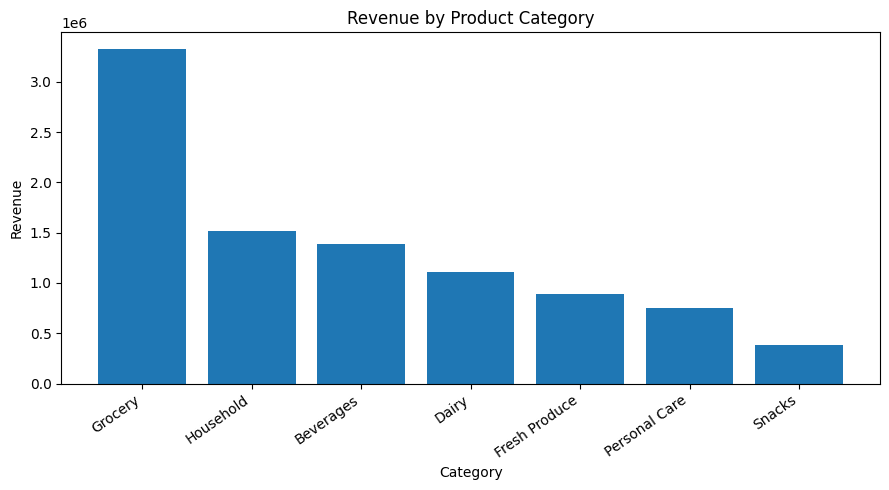

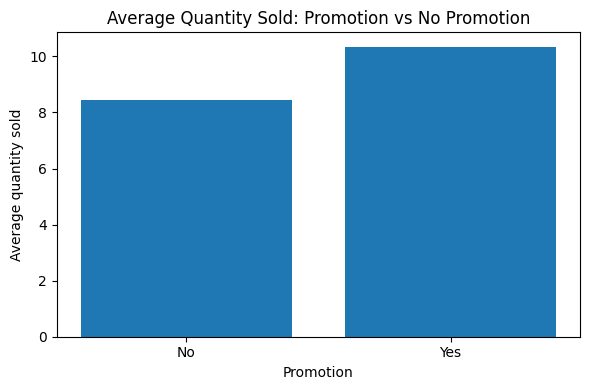

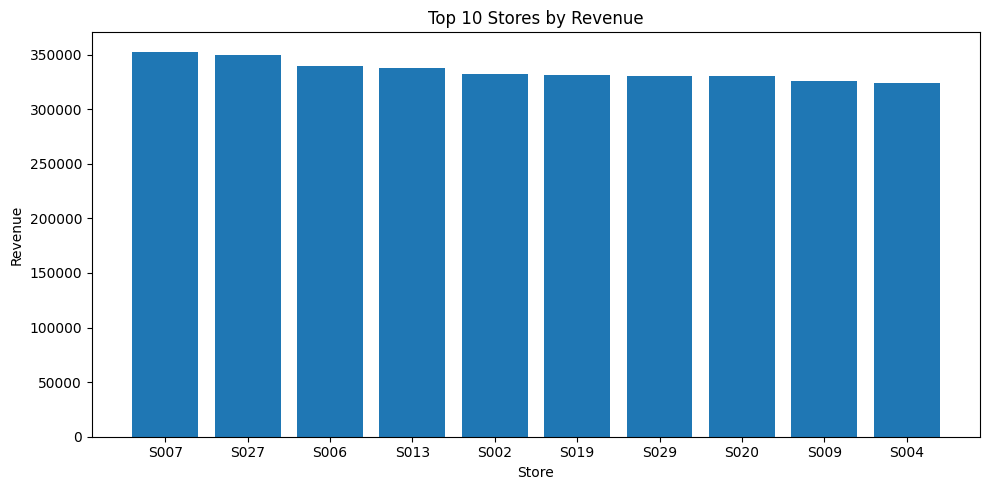

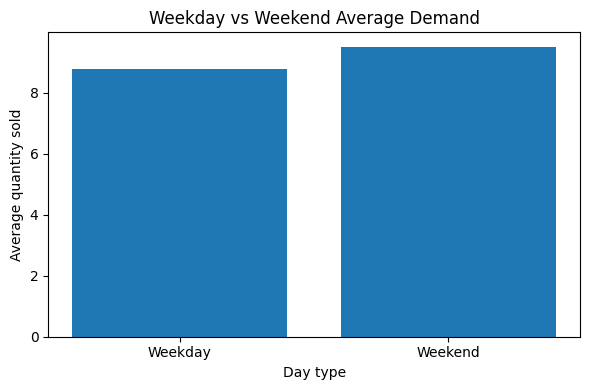

In [ ]:
plt.figure(figsize=(9, 5))
plt.bar(category_revenue["category"], category_revenue["revenue"])
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(promotion_summary["promotion"], promotion_summary["quantity_sold"])
plt.title("Average Quantity Sold: Promotion vs No Promotion")
plt.xlabel("Promotion")
plt.ylabel("Average quantity sold")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
top_stores = store_sales.head(10)
plt.bar(top_stores["store_id"], top_stores["revenue"])
plt.title("Top 10 Stores by Revenue")
plt.xlabel("Store")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(weekend_summary["day_type"], weekend_summary["quantity_sold"])
plt.title("Weekday vs Weekend Average Demand")
plt.xlabel("Day type")
plt.ylabel("Average quantity sold")
plt.tight_layout()
plt.show()

## Round 2 — Cell 7: Feature engineering and target selection

In [ ]:
# Target: quantity_sold
# Predictors are available at transaction time; transaction_id, product_name and revenue are excluded.
features = [
    "product_id", "category", "brand", "unit_price", "discount_pct",
    "promotion", "customer_count", "weather", "holiday", "weekend",
    "opening_stock", "store_id", "city", "store_type", "region",
    "month", "day_of_week"
]
target = "quantity_sold"

X = df[features].copy()
y = df[target].copy()

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()

print("Input features:", features)
print("Target variable:", target)
print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)

Input features: ['product_id', 'category', 'brand', 'unit_price', 'discount_pct', 'promotion', 'customer_count', 'weather', 'holiday', 'weekend', 'opening_stock', 'store_id', 'city', 'store_type', 'region', 'month', 'day_of_week']
Target variable: quantity_sold
Categorical features: ['product_id', 'category', 'brand', 'promotion', 'weather', 'holiday', 'store_id', 'city', 'store_type', 'region']
Numeric features: ['unit_price', 'discount_pct', 'customer_count', 'weekend', 'opening_stock', 'month', 'day_of_week']


## Round 2 — Cell 8: Train and evaluate Random Forest

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=150, random_state=42, min_samples_leaf=2, n_jobs=-1
    ))
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Algorithm: Random Forest Regressor")
print(f"Train rows: {len(X_train):,}; Test rows: {len(X_test):,}")
print(f"MAE: {mae:.3f} units")
print(f"RMSE: {rmse:.3f} units")
print(f"R² score: {r2:.4f}")
print("\nUse these actual printed metrics in your assessment sheet.")

Algorithm: Random Forest Regressor
Train rows: 7,972; Test rows: 1,994
MAE: 2.753 units
RMSE: 3.496 units
R² score: 0.0184

Use these actual printed metrics in your assessment sheet.


## Round 2 — Cell 9: Feature importance

,feature,importance
2,customer_count,0.146130
0,unit_price,0.133853
4,opening_stock,0.120296
5,month,0.070573
6,day_of_week,0.046626
1,discount_pct,0.046044
46,promotion_Yes,0.040077
45,promotion_No,0.029552
50,weather_Sunny,0.013426
94,store_type_Supermarket,0.013097


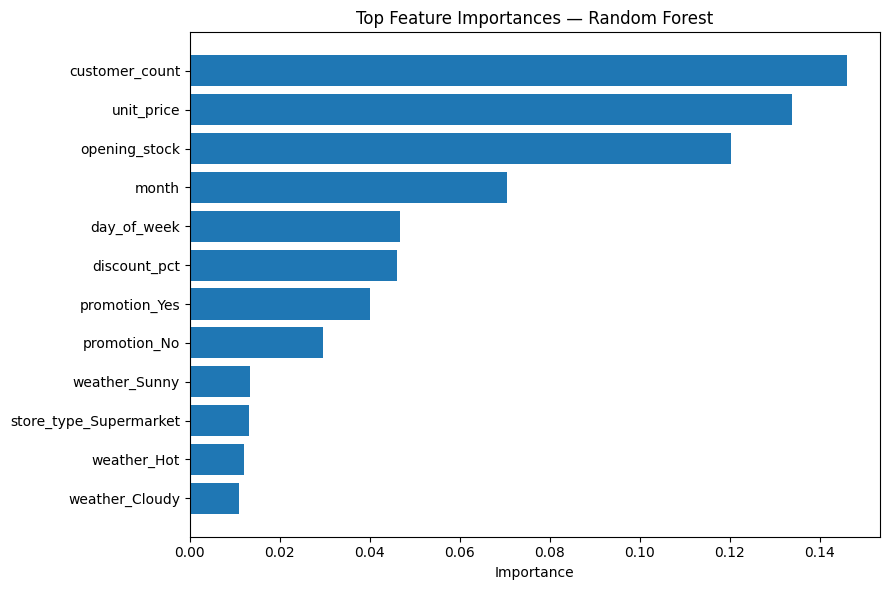

In [ ]:
# Retrieve feature names after one-hot encoding
fitted_preprocessor = model.named_steps["preprocessor"]
encoded_cat_names = (
    fitted_preprocessor.named_transformers_["cat"]
    .named_steps["onehot"]
    .get_feature_names_out(categorical_features)
)
all_feature_names = numeric_features + list(encoded_cat_names)
importances = model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "feature": all_feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

display(importance_df.head(15))

top_importance = importance_df.head(12).sort_values("importance")
plt.figure(figsize=(9, 6))
plt.barh(top_importance["feature"], top_importance["importance"])
plt.title("Top Feature Importances — Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Round 3 — Cell 10: Inventory insights and products needing attention

In [ ]:
# Use a practical stock flag. This is a simple screening rule, not a forecast.
df["below_reorder_level"] = df["closing_stock"] <= 20

product_inventory = (
    df.groupby(["product_id", "product_name", "category"], as_index=False)
      .agg(
          total_units_sold=("quantity_sold", "sum"),
          total_revenue=("revenue", "sum"),
          average_closing_stock=("closing_stock", "mean"),
          low_stock_records=("below_reorder_level", "sum"),
          records=("transaction_id", "count")
      )
)
product_inventory["low_stock_rate_pct"] = (
    product_inventory["low_stock_records"] / product_inventory["records"] * 100
)
product_inventory = product_inventory.sort_values(
    ["low_stock_rate_pct", "total_units_sold"], ascending=[False, False]
)

print("Products to review (highest low-stock rate):")
display(product_inventory.head(10))

low_stock_rate = df["below_reorder_level"].mean() * 100
print(f"Records flagged as low stock using closing_stock <= 20: {low_stock_rate:.2f}%")

store_summary = (
    df.groupby(["store_id", "city", "store_type"], as_index=False)
      .agg(total_revenue=("revenue", "sum"), units_sold=("quantity_sold", "sum"))
      .sort_values("total_revenue", ascending=False)
)
display(store_summary.head(10))

Products to review (highest low-stock rate):


,product_id,product_name,category,total_units_sold,total_revenue,average_closing_stock,low_stock_records,records,low_stock_rate_pct
15,P016,Coffee 200g,Beverages,4516,878202.9050,89.756701,37,485,7.628866
8,P009,Laundry Detergent,Household,4912,833872.8952,91.177122,41,542,7.564576
13,P014,Tomatoes 1kg,Fresh Produce,4870,205315.8388,90.462857,38,525,7.238095
7,P008,Mineral Water 1L,Beverages,4432,82243.7250,92.701863,34,483,7.039337
2,P003,Milk 1L,Dairy,4285,128378.0323,89.803279,34,488,6.967213
3,P004,Cheese 200g,Dairy,4585,618527.5205,92.966469,35,507,6.903353
1,P002,Wheat Flour 2kg,Grocery,4297,462974.5372,92.666667,31,474,6.540084
14,P015,Eggs 12 Pack,Dairy,4569,363447.3546,92.364356,33,505,6.534653
18,P019,Chocolate Bar,Snacks,4259,159046.5953,92.717300,29,474,6.118143
9,P010,Dishwash Liquid,Household,4558,381743.5556,91.769380,31,516,6.007752


Records flagged as low stock using closing_stock <= 20: 5.74%


,store_id,city,store_type,total_revenue,units_sold
623,S026,Pune,Supermarket,40095.3227,250
635,S027,Hyderabad,Supermarket,37420.0962,325
380,S016,Mysuru,Supermarket,36700.1203,312
167,S007,Pune,Supermarket,36454.3504,274
278,S012,Kochi,Supermarket,35067.8309,250
353,S015,Madurai,Supermarket,33797.6649,308
221,S010,Chennai,Supermarket,33773.5060,272
458,S020,Bengaluru,Supermarket,33432.7653,231
530,S023,Bengaluru,Supermarket,33431.5183,254
521,S022,Madurai,Supermarket,33408.7498,295


## Round 3 — Cell 11: Summary findings and recommendations

In [ ]:
top_store = store_summary.iloc[0]
top_low_stock_product = product_inventory.iloc[0]
print("BUSINESS INSIGHTS")
print(f"1. Highest revenue category: {top_category['category']} "
      f"({top_category['revenue']:,.2f} revenue).")
if "Yes" in promo_dict and "No" in promo_dict:
    print(f"2. Average quantity sold with promotion is {promo_dict['Yes']:.2f}; "
          f"without promotion is {promo_dict['No']:.2f}.")
print(f"3. Highest-revenue store in the cleaned data: {top_store['store_id']} "
      f"({top_store['city']}) with {top_store['total_revenue']:,.2f} revenue.")
print(f"4. Product to review first by the simple low-stock rule: "
      f"{top_low_stock_product['product_name']} "
      f"(low-stock record rate {top_low_stock_product['low_stock_rate_pct']:.2f}%).")

print("\nPRACTICAL RECOMMENDATIONS")
print("1. Review products with high low-stock rates and replenish after checking current stock and supplier lead time.")
print("2. Compare promotion-period sales with regular sales before planning future promotions and inventory.")

BUSINESS INSIGHTS
1. Highest revenue category: Grocery (3,325,778.40 revenue).
2. Average quantity sold with promotion is 10.34; without promotion is 8.43.
3. Highest-revenue store in the cleaned data: S026 (Pune) with 40,095.32 revenue.
4. Product to review first by the simple low-stock rule: Coffee 200g (low-stock record rate 7.63%).

PRACTICAL RECOMMENDATIONS
1. Review products with high low-stock rates and replenish after checking current stock and supplier lead time.
2. Compare promotion-period sales with regular sales before planning future promotions and inventory.
